# Parte 5 · ¿Un pedido llegará tarde?
MercaLlano S.A.S. · Candidata: Isabella

Objetivo: cuando un pedido se confirma (antes del despacho), estimar qué tan probable es que **no** llegue el día prometido, para poder actuar (cambiar de transportadora, despachar antes o avisar al cliente).

El dataset sale de la vista `dw.vw_dataset_ml` (archivo `vw_dataset_ml.sql`) y se exportó a `dataset_ml.csv`.

## 1. Variable objetivo
- **`entregado_tarde` = 1** si la fecha real de entrega es posterior a la fecha prometida; **0** si llegó a tiempo o antes (regla de negocio del enunciado). No existe como columna: se calcula en el dw.
- **Se usan** pedidos *Entregado* y *Devuelto*: ambos tienen fecha real de entrega, así que sabemos si cumplieron.
- **Se dejan fuera:** *Cancelado* y *Anulado* (nunca se entregaron, no hay etiqueta) y 17 líneas con entrega real anterior al pedido (error de datos, ya rechazadas en el ETL).

## 2. Variables predictoras: ¿la uso o no?
Regla: solo información que existe **al confirmar el pedido**.

| Columna | ¿La uso? | Por qué |
|---|---|---|
| canal, método de pago, franja de entrega, segmento | Sí | Se conocen al confirmar |
| ciudad/departamento de destino, bodega, transportadora, distancia | Sí | El pedido ya está asignado |
| n° de líneas, unidades, peso, venta bruta, % refrigerado | Sí | Contenido del pedido |
| días prometidos (prometida − pedido) | Sí | La promesa se hace al confirmar |
| cruza la vía, estado de la vía ese día, lluvia y alerta en destino ese día | Sí | Reporte diario publicado el día del pedido |
| día de semana, hora, mes (creadas desde la fecha) | Sí | Salen de `fecha_pedido` |
| pedidos previos, % tarde previo del cliente, días desde su último pedido | Sí | Historial **solo del pasado**: cuenta únicamente entregas que ya habían llegado antes del día del pedido |
| fecha_entrega_real, días de retraso, horas hasta entrega | **No** | Fuga de información: solo se conocen después |
| calificación, reclamo, novedad de la transportadora, estado final | **No** | Ocurren después de la entrega |
| id_pedido, documento, nombre, email, dirección | **No** | Identificadores, no explican el retraso |

## 3. Datos y balance de clases

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

# En Colab: sube dataset_ml.csv con el panel de archivos (icono de carpeta) o con files.upload()
df = pd.read_csv('dataset_ml.csv', parse_dates=['fecha_pedido'])
print(df.shape)
print(df.dtypes)

(2803, 25)
id_pedido                       str
fecha_pedido         datetime64[us]
canal                           str
segmento                        str
ciudad_destino                  str
departamento                    str
bodega                          str
transportadora                  str
distancia_km                float64
metodo_pago                     str
franja_entrega                  str
n_lineas                      int64
unidades                    float64
peso_kg                     float64
venta_bruta                 float64
pct_refrigerado             float64
dias_prometidos               int64
cruza_via                     int64
estado_via                      str
lluvia_mm_destino           float64
alerta_destino                  str
pedidos_previos               int64
pct_tarde_previo            float64
dias_desde_ultimo           float64
entregado_tarde               int64
dtype: object


In [2]:
y = 'entregado_tarde'
print(df[y].value_counts())
print((df[y].value_counts(normalize=True) * 100).round(1))

entregado_tarde
0    2075
1     728
Name: count, dtype: int64
entregado_tarde
0    74.0
1    26.0
Name: proportion, dtype: float64


## 4. Variables nuevas y exploración
Se crean variables de calendario y dos banderas simples. Las gráficas sirven para decidir qué incluir.

In [3]:
df['dia_semana'] = df['fecha_pedido'].dt.dayofweek          # 0 = lunes ... 6 = domingo
df['hora_pedido'] = df['fecha_pedido'].dt.hour
df['mes'] = df['fecha_pedido'].dt.month
df['pedido_fin_de_semana'] = (df['dia_semana'] >= 5).astype(int)
df['alerta_destino'] = df['alerta_destino'].fillna('Sin alerta')
df['estado_via'] = df['estado_via'].fillna('Sin dato')
df['cliente_nuevo'] = (df['pedidos_previos'] == 0).astype(int)
df['lluvia_fuerte'] = (df['lluvia_mm_destino'].fillna(0) >= 20).astype(int)

C:\Users\Usuario\AppData\Local\Temp\ipykernel_23404\1533186271.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dia_semana'] = df['fecha_pedido'].dt.dayofweek          # 0 = lunes ... 6 = domingo


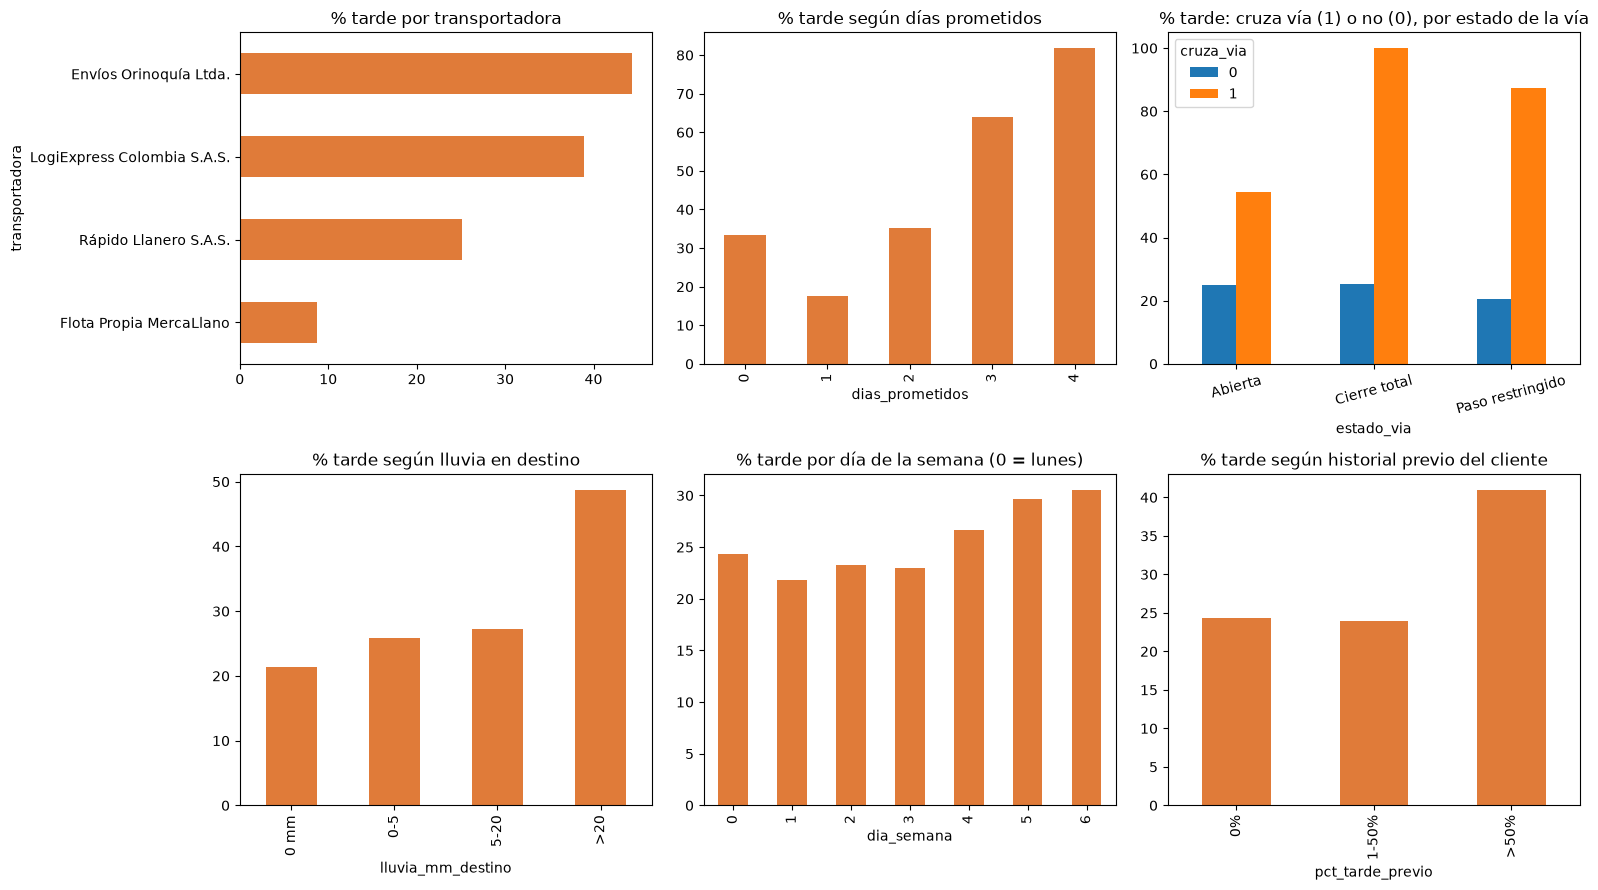

                              mean  count
transportadora                           
Envíos Orinoquía Ltda.       0.444    250
Flota Propia MercaLlano      0.087    846
LogiExpress Colombia S.A.S.  0.390    824
Rápido Llanero S.A.S.        0.251    883
                  mean  count
dias_prometidos              
0                0.333    150
1                0.177   1743
2                0.351    741
3                0.639    158
4                0.818     11
                             mean  count
cruza_via estado_via                    
0         Abierta           0.251   2404
          Cierre total      0.252    115
          Paso restringido  0.205    185
1         Abierta           0.545     88
          Cierre total      1.000      3
          Paso restringido  0.875      8
                    mean  count
lluvia_mm_destino              
(-1, 0]            0.214   1603
(0, 5]             0.259    359
(5, 20]            0.273    539
(20, 500]          0.488    285
dia_semana
0    0.

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
df.groupby('transportadora')[y].mean().mul(100).sort_values().plot.barh(ax=ax[0, 0], color='#e07b39')
ax[0, 0].set_title('% tarde por transportadora')
df.groupby('dias_prometidos')[y].mean().mul(100).plot.bar(ax=ax[0, 1], color='#e07b39')
ax[0, 1].set_title('% tarde según días prometidos')
df.groupby(['cruza_via', 'estado_via'])[y].mean().mul(100).unstack(0).plot.bar(ax=ax[0, 2])
ax[0, 2].set_title('% tarde: cruza vía (1) o no (0), por estado de la vía')
ax[0, 2].tick_params(axis='x', rotation=15)
df.groupby(pd.cut(df['lluvia_mm_destino'], [-1, 0, 5, 20, 500], labels=['0 mm', '0-5', '5-20', '>20']),
           observed=True)[y].mean().mul(100).plot.bar(ax=ax[1, 0], color='#e07b39')
ax[1, 0].set_title('% tarde según lluvia en destino')
df.groupby('dia_semana')[y].mean().mul(100).plot.bar(ax=ax[1, 1], color='#e07b39')
ax[1, 1].set_title('% tarde por día de la semana (0 = lunes)')
df.groupby(pd.cut(df['pct_tarde_previo'], [-0.01, 0, 0.5, 1.0], labels=['0%', '1-50%', '>50%']),
           observed=True)[y].mean().mul(100).plot.bar(ax=ax[1, 2], color='#e07b39')
ax[1, 2].set_title('% tarde según historial previo del cliente')
plt.tight_layout(); plt.savefig('eda.png', dpi=110); plt.show()
# Resumen numérico de lo que muestran las gráficas
print(df.groupby('transportadora')[y].agg(['mean', 'count']).round(3))
print(df.groupby('dias_prometidos')[y].agg(['mean', 'count']).round(3))
print(df.groupby(['cruza_via', 'estado_via'])[y].agg(['mean', 'count']).round(3))
print(df.groupby(pd.cut(df['lluvia_mm_destino'], [-1, 0, 5, 20, 500]), observed=True)[y].agg(['mean', 'count']).round(3))
print(df.groupby('dia_semana')[y].mean().round(3))
print(df.groupby(pd.cut(df['distancia_km'], [0, 10, 30, 80, 500]), observed=True)[y].agg(['mean', 'count']).round(3))  # ¡la distancia pesa mucho!
print(df.groupby(pd.cut(df['pct_tarde_previo'], [-0.01, 0, 0.5, 1.0]), observed=True)[y].agg(['mean', 'count']).round(3))

## 5. Validación: separar por fecha, no al azar
El modelo se usará con pedidos **futuros**. Por eso se entrena con lo más antiguo, se ajusta el umbral con un tramo intermedio (validación) y se evalúa con lo más reciente (prueba). Una separación al azar dejaría al modelo "ver el futuro" y daría resultados demasiado optimistas.

In [5]:
fecha_val, fecha_test = pd.Timestamp('2026-01-01'), pd.Timestamp('2026-03-01')
train = df[df.fecha_pedido < fecha_val]
val = df[(df.fecha_pedido >= fecha_val) & (df.fecha_pedido < fecha_test)]
test = df[df.fecha_pedido >= fecha_test]
for n, p in [('train', train), ('val', val), ('test', test)]:
    print(n, len(p), f"{p[y].mean():.1%} tarde", p.fecha_pedido.min().date(), '->', p.fecha_pedido.max().date())

train 1853 25.8% tarde 2025-01-01 -> 2025-12-31
val 332 22.3% tarde 2026-01-01 -> 2026-02-28
test 618 28.3% tarde 2026-03-01 -> 2026-06-30


## 6. Modelos
Dos referencias sencillas (tasa global y tasa por transportadora) y tres modelos: regresión logística, Random Forest y Gradient Boosting. Se compara con **PR-AUC** y **ROC-AUC** porque solo ~1 de cada 4 pedidos llega tarde y la exactitud (accuracy) engaña con clases desbalanceadas.

In [6]:
num = ['distancia_km', 'n_lineas', 'unidades', 'peso_kg', 'venta_bruta', 'pct_refrigerado', 'dias_prometidos',
       'lluvia_mm_destino', 'pedidos_previos', 'pct_tarde_previo', 'dias_desde_ultimo',
       'dia_semana', 'hora_pedido', 'mes', 'pedido_fin_de_semana', 'cruza_via', 'cliente_nuevo', 'lluvia_fuerte']
cat = ['canal', 'segmento', 'departamento', 'bodega', 'transportadora', 'metodo_pago', 'franja_entrega',
       'estado_via', 'alerta_destino']
pre_lin = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])
pre_tree = ColumnTransformer([
    ('num', SimpleImputer(strategy='median', add_indicator=True), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])
X = lambda p: p[num + cat]

In [7]:
modelos = {
    'Baseline (siempre la tasa global)': DummyClassifier(strategy='prior'),
    'Regresión logística': Pipeline([('pre', pre_lin),
        ('m', LogisticRegression(max_iter=2000, class_weight='balanced', C=0.5))]),
    'Random Forest': Pipeline([('pre', pre_tree),
        ('m', RandomForestClassifier(n_estimators=400, min_samples_leaf=10, class_weight='balanced_subsample',
                                     random_state=42, n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('pre', pre_tree),
        ('m', GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8,
                                         random_state=42))]),
}
prob = {}
for n, m in modelos.items():
    m.fit(X(train), train[y])
    prob[n] = {'val': m.predict_proba(X(val))[:, 1], 'test': m.predict_proba(X(test))[:, 1]}
# Baseline 2 (regla simple): tasa histórica de tardanza de cada transportadora (calculada solo con train)
tasa_transp = train.groupby('transportadora')[y].mean()
prob['Baseline regla: tasa por transportadora'] = {
    'val': val.transportadora.map(tasa_transp).values, 'test': test.transportadora.map(tasa_transp).values}

In [8]:
filas = []
for n, p in prob.items():
    filas.append({'modelo': n,
                  'ROC-AUC val': roc_auc_score(val[y], p['val']), 'PR-AUC val': average_precision_score(val[y], p['val']),
                  'ROC-AUC test': roc_auc_score(test[y], p['test']), 'PR-AUC test': average_precision_score(test[y], p['test'])})
res = pd.DataFrame(filas).set_index('modelo').round(3)
print(res)
print('PR-AUC de azar (= tasa de tardíos en test):', round(test[y].mean(), 3))

                                         ROC-AUC val  PR-AUC val  \
modelo                                                             
Baseline (siempre la tasa global)              0.500       0.223   
Regresión logística                            0.796       0.553   
Random Forest                                  0.778       0.516   
Gradient Boosting                              0.781       0.539   
Baseline regla: tasa por transportadora        0.696       0.343   

                                         ROC-AUC test  PR-AUC test  
modelo                                                              
Baseline (siempre la tasa global)               0.500        0.283  
Regresión logística                             0.809        0.653  
Random Forest                                   0.802        0.642  
Gradient Boosting                               0.813        0.650  
Baseline regla: tasa por transportadora         0.699        0.409  
PR-AUC de azar (= tasa de tardíos en tes

## 7. Métricas y umbral
Se elige el modelo con mejor PR-AUC en validación. El umbral es el que da la mayor precisión exigiendo atrapar al menos el 60 % de los pedidos tardíos. La matriz de confusión está en `tn, fp, fn, tp`.

In [9]:
mejor = res.loc[['Regresión logística', 'Random Forest', 'Gradient Boosting'], 'PR-AUC val'].idxmax()
print('Modelo elegido (mejor PR-AUC en validación):', mejor)

def metricas(yv, pv, thr):
    pred = (pv >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yv, pred).ravel()
    return dict(umbral=round(thr, 3), tn=tn, fp=fp, fn=fn, tp=tp,
                precision=precision_score(yv, pred, zero_division=0), recall=recall_score(yv, pred), f1=f1_score(yv, pred))

barrido = pd.DataFrame([metricas(val[y], prob[mejor]['val'], t) for t in np.arange(0.05, 0.95, 0.025)])
print(barrido.round(2).to_string())
# Regla de negocio: la mayor precisión posible exigiendo que atrape al menos 60% de los tardíos
cand = barrido[barrido.recall >= 0.60]
umbral = float(cand.sort_values('precision', ascending=False).iloc[0]['umbral']) if len(cand) else 0.5
print('Umbral elegido:', umbral)
print('TEST con ese umbral')
print(pd.Series(metricas(test[y], prob[mejor]['test'], umbral)).round(3))

Modelo elegido (mejor PR-AUC en validación): Regresión logística


    umbral   tn   fp  fn  tp  precision  recall    f1
0     0.05    2  256   0  74       0.22    1.00  0.37
1     0.08   10  248   0  74       0.23    1.00  0.37
2     0.10   25  233   0  74       0.24    1.00  0.39
3     0.12   35  223   0  74       0.25    1.00  0.40
4     0.15   46  212   0  74       0.26    1.00  0.41
5     0.18   67  191   1  73       0.28    0.99  0.43
6     0.20   86  172   3  71       0.29    0.96  0.45
7     0.22   98  160   3  71       0.31    0.96  0.47
8     0.25  111  147   6  68       0.32    0.92  0.47
9     0.28  119  139   8  66       0.32    0.89  0.47
10    0.30  132  126   8  66       0.34    0.89  0.50
11    0.32  143  115  10  64       0.36    0.86  0.51
12    0.35  150  108  12  62       0.36    0.84  0.51
13    0.38  160   98  15  59       0.38    0.80  0.51
14    0.40  169   89  16  58       0.39    0.78  0.52
15    0.42  176   82  17  57       0.41    0.77  0.54
16    0.45  184   74  19  55       0.43    0.74  0.54
17    0.48  193   65  23  51

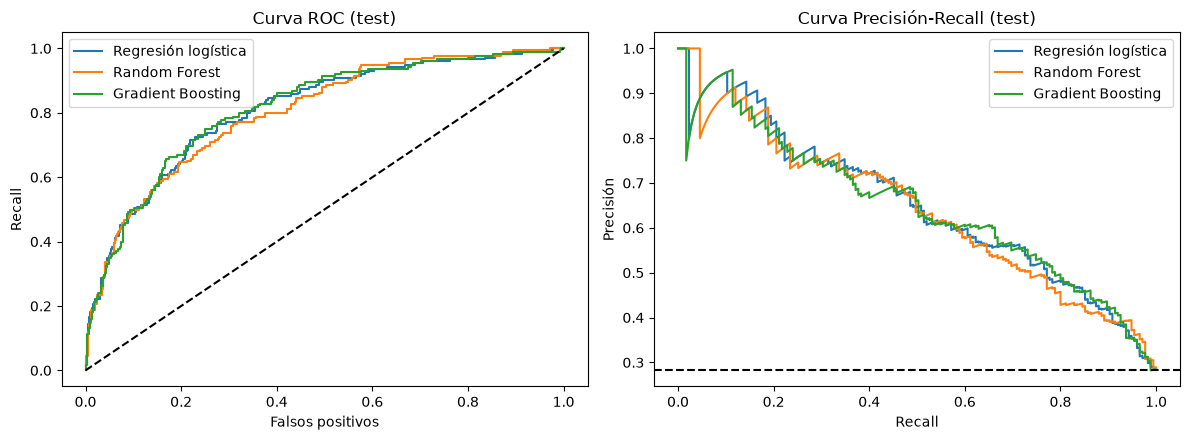

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n in ['Regresión logística', 'Random Forest', 'Gradient Boosting']:
    f, t, _ = roc_curve(test[y], prob[n]['test']); ax[0].plot(f, t, label=n)
    p, r, _ = precision_recall_curve(test[y], prob[n]['test']); ax[1].plot(r, p, label=n)
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_title('Curva ROC (test)')
ax[0].set_xlabel('Falsos positivos'); ax[0].set_ylabel('Recall'); ax[0].legend()
ax[1].axhline(test[y].mean(), color='k', ls='--'); ax[1].set_title('Curva Precisión-Recall (test)')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precisión'); ax[1].legend()
plt.tight_layout(); plt.savefig('curvas.png', dpi=110); plt.show()

## 8. Variables más influyentes y alertas por día

In [11]:
imp = permutation_importance(modelos[mejor], X(test), test[y], scoring='average_precision',
                             n_repeats=10, random_state=0, n_jobs=1)
imp = pd.Series(imp.importances_mean, index=num + cat).sort_values(ascending=False)
print(imp.head(10).round(4))

distancia_km            0.2149
transportadora          0.1092
lluvia_mm_destino       0.1006
venta_bruta             0.0266
segmento                0.0226
franja_entrega          0.0202
pct_tarde_previo        0.0158
pedido_fin_de_semana    0.0157
n_lineas                0.0132
dia_semana              0.0117
dtype: float64


In [12]:
t = test.assign(p=prob[mejor]['test'])
t['alerta'] = t.p >= umbral
dias = t.fecha_pedido.dt.normalize().nunique()
print('Pedidos alertados por día (promedio):', round(t.alerta.sum() / dias, 1), 'de', round(len(t) / dias, 1))
print('Tasa real de tardanza entre alertados:', round(t[t.alerta][y].mean(), 3), '| entre no alertados:', round(t[~t.alerta][y].mean(), 3))

Pedidos alertados por día (promedio): 1.9 de 5.1
Tasa real de tardanza entre alertados: 0.547 | entre no alertados: 0.124


## 9. Conclusión para el negocio
**Qué encontramos.** Cerca de 1 de cada 4 pedidos llega tarde. El modelo (regresión logística) sirve: de los pedidos que marca como riesgosos, **más de la mitad (55 %) sí llegan tarde**, contra un 12 % entre los que no marca. Detecta **7 de cada 10** pedidos que se van a retrasar.

**Qué pesa más.** (1) La **distancia** del pedido, (2) **qué transportadora** lo lleva y (3) la **lluvia** en el destino ese día. El estado de la vía y el historial del cliente pesan menos.

**Umbral recomendado: 0,50.** Con él se alertan en promedio unos 2 pedidos de cada 5 que entran al día. Si la operación puede revisar más pedidos, se puede bajar el umbral: se atrapan más retrasos, pero con más falsas alarmas.

**Qué acción dispararía.** Cuando un pedido sale alertado, antes de despacharlo: cambiar a una transportadora o a la flota propia, adelantar el despacho si hay lluvia, y avisarle al cliente que puede demorar.

**Límites.** El modelo se probó con 2026 (los pedidos más recientes) y debe reentrenarse cada cierto tiempo. Usa el reporte de lluvia del día del pedido: si ese reporte llega después de confirmar el pedido, hay que usar el pronóstico.